In [ ]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))


AssertionError: Torch not compiled with CUDA enabled

In [ ]:
import os
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_REVOKED'

In [ ]:
!pip install -q --upgrade kaggle
!kaggle competitions download -c dog-breed-identification -p /content/data
!unzip -q /content/data/dog-breed-identification.zip -d /content/data
!ls /content/data

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 10.7 MB/s eta 0:00:00
100% 691M/691M [00:41<00:00, 17.6MB/s]

dog-breed-identification.zip  labels.csv  sample_submission.csv  test  train


In [ ]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [ ]:
!ls /content/data

dog-breed-identification.zip  labels.csv  sample_submission.csv  test  train


In [ ]:
import pandas as pd, os
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

DATA = '/content/data'
df = pd.read_csv(f'{DATA}/labels.csv')
classes = sorted(df['breed'].unique())
c2i = {c: i for i, c in enumerate(classes)}
df['label'] = df['breed'].map(c2i)

train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)

norm = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
train_tf = transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(), transforms.ToTensor(), norm])
val_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(), norm])

class DogDS(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        img = Image.open(f"{DATA}/train/{r['id']}.jpg").convert('RGB')
        return self.tf(img), r['label']

train_dl = DataLoader(DogDS(train_df, train_tf), batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(DogDS(val_df, val_tf), batch_size=64, num_workers=2)
print(len(train_df), len(val_df), len(classes))

8177 2045 120


In [ ]:
import torch.nn as nn
from torchvision import models

device = 'cuda'
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
for p in model.parameters(): p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


In [ ]:
EPOCHS = 8
for ep in range(EPOCHS):
    model.train(); tl = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward(); optimizer.step()
        tl += loss.item()
    model.eval(); correct = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    print(f"Epoch {ep+1}/{EPOCHS} | train loss {tl/len(train_dl):.3f} | val acc {correct/len(val_df):.3f}")

Epoch 1/8 | train loss 3.512 | val acc 0.738
Epoch 2/8 | train loss 1.974 | val acc 0.819
Epoch 3/8 | train loss 1.447 | val acc 0.840
Epoch 4/8 | train loss 1.189 | val acc 0.843
Epoch 5/8 | train loss 1.079 | val acc 0.846
Epoch 6/8 | train loss 0.970 | val acc 0.857
Epoch 7/8 | train loss 0.917 | val acc 0.851
Epoch 8/8 | train loss 0.858 | val acc 0.852


In [ ]:
torch.save(model.state_dict(), '/content/dog_breed_model.pth')
from google.colab import files
files.download('/content/dog_breed_model.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

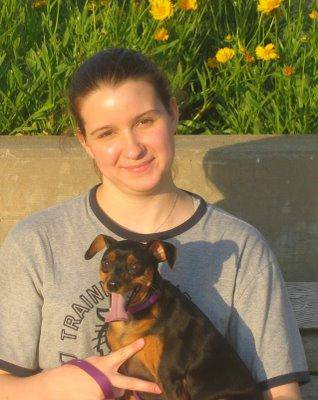

Actual: miniature_pinscher | Predicted: miniature_pinscher


In [ ]:
import random
r = val_df.sample(1).iloc[0]
img = Image.open(f"{DATA}/train/{r['id']}.jpg").convert('RGB')
model.eval()
with torch.no_grad():
    pred = model(val_tf(img).unsqueeze(0).to(device)).argmax(1).item()
display(img)
print("Actual:", r['breed'], "| Predicted:", classes[pred])

In [ ]:
!pip install -q ultralytics opencv-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 76.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.9 MB/s eta 0:00:00


In [ ]:
import cv2, torch
from PIL import Image
from ultralytics import YOLO

INPUT = '/content/contentinput.mp4.mp4'
OUTPUT = '/content/output.mp4'

detector = YOLO('yolov8n.pt')
model.eval()

cap = cv2.VideoCapture(INPUT)
if not cap.isOpened():
    raise FileNotFoundError(f"Video open nahi hui: {INPUT}")

w = int(cap.get(3))
h = int(cap.get(4))
fps = cap.get(cv2.CAP_PROP_FPS) or 25
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
out = cv2.VideoWriter(OUTPUT, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

DOG = 16
n = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    res = detector(frame, verbose=False)[0]
    for b in res.boxes:
        if int(b.cls) != DOG or float(b.conf) < 0.4:
            continue
        x1, y1, x2, y2 = map(int, b.xyxy[0])
        x1 = max(x1, 0)
        y1 = max(y1, 0)
        x2 = min(x2, w)
        y2 = min(y2, h)
        crop = frame[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        img = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        with torch.no_grad():
            inp = val_tf(img).unsqueeze(0).to(device)
            p = torch.softmax(model(inp), 1)[0]
        conf, idx = p.max(0)
        label = f"{classes[idx.item()]} {conf.item():.2f}"
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(frame, label, (x1, max(y1 - 8, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    out.write(frame)
    n += 1
    if n % 30 == 0:
        print(f"{n}/{total} frames done")

cap.release()
out.release()
print("Done! Frames processed:", n)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
30/308 frames done
60/308 frames done
90/308 frames done
120/308 frames done
150/308 frames done
180/308 frames done
210/308 frames done
240/308 frames done
270/308 frames done
300/308 frames done
Done! Frames processed: 308


In [ ]:
!ffmpeg -y -loglevel error -i /content/output.mp4 -vcodec libx264 -pix_fmt yuv420p /content/output_final.mp4

from google.colab import files
files.download('/content/output_final.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import cv2, torch, numpy as np
from collections import defaultdict, Counter
from PIL import Image
from ultralytics import YOLO

INPUT = '/content/contentinput.mp4.mp4'
OUTPUT = '/content/output.mp4'

detector = YOLO('yolov8n.pt')
model.eval()

cap = cv2.VideoCapture(INPUT)
if not cap.isOpened():
    raise FileNotFoundError(f"Video open nahi hui: {INPUT}")

w = int(cap.get(3))
h = int(cap.get(4))
fps = cap.get(cv2.CAP_PROP_FPS) or 25
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
out = cv2.VideoWriter(OUTPUT, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

scale = max(w, h) / 1000.0
font_scale = max(0.9, 1.2 * scale)
thick = max(2, int(2 * scale))

DOG = 16
MIN_CONF = 0.4
MIN_SIDE = 60
MIN_FRAMES = 5          # itne frames dikhe tabhi dog ginna
history = defaultdict(list)
current_breed = {}      # dog ID -> abhi ki breed
n = 0

def draw_panel(frame, lines):
    pad = 10
    sizes = [cv2.getTextSize(t, cv2.FONT_HERSHEY_SIMPLEX, font_scale * 0.8, thick) for t in lines]
    pw = max(s[0][0] for s in sizes) + 2 * pad
    lh = max(s[0][1] + s[1] for s in sizes) + 8
    ph = lh * len(lines) + 2 * pad
    cv2.rectangle(frame, (10, 10), (10 + pw, 10 + ph), (0, 0, 0), -1)
    for i, t in enumerate(lines):
        cv2.putText(frame, t, (10 + pad, 10 + pad + lh * (i + 1) - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale * 0.8, (255, 255, 255), thick)

while True:
    ok, frame = cap.read()
    if not ok:
        break
    res = detector.track(frame, persist=True, classes=[DOG], verbose=False)[0]
    in_frame = 0

    if res.boxes.id is not None:
        for b in res.boxes:
            if b.id is None or float(b.conf) < MIN_CONF:
                continue
            tid = int(b.id)
            x1, y1, x2, y2 = map(int, b.xyxy[0])
            x1 = max(x1, 0)
            y1 = max(y1, 0)
            x2 = min(x2, w)
            y2 = min(y2, h)
            if (x2 - x1) < MIN_SIDE or (y2 - y1) < MIN_SIDE:
                continue
            crop = frame[y1:y2, x1:x2]
            img = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
            with torch.no_grad():
                inp = val_tf(img).unsqueeze(0).to(device)
                p = torch.softmax(model(inp), 1)[0].cpu().numpy()

            history[tid].append(p)
            recent = np.mean(history[tid][-15:], axis=0)
            idx = int(recent.argmax())
            conf = float(recent[idx])
            current_breed[tid] = classes[idx]
            in_frame += 1

            label = f"{classes[idx].replace('_', ' ')} {conf*100:.0f}%"
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), thick + 1)
            (tw, th), bl = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thick)
            ty = max(y1, th + bl + 6)
            cv2.rectangle(frame, (x1, ty - th - bl - 6), (x1 + tw + 10, ty), (0, 0, 0), -1)
            cv2.putText(frame, label, (x1 + 5, ty - bl - 2),
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 255, 0), thick)

    # breed-wise count: sirf wahi dogs jo kam se kam MIN_FRAMES frames dikhe
    counts = Counter(
        current_breed[t].replace('_', ' ')
        for t in current_breed if len(history[t]) >= MIN_FRAMES
    )
    lines = [f"Dogs in frame: {in_frame}", f"Total dogs: {sum(counts.values())}"]
    for breed, c in counts.most_common():
        lines.append(f"{breed}: {c}")
    draw_panel(frame, lines)

    out.write(frame)
    n += 1
    if n % 30 == 0:
        print(f"{n}/{total} frames done")

cap.release()
out.release()

final = Counter(
    current_breed[t].replace('_', ' ')
    for t in current_breed if len(history[t]) >= MIN_FRAMES
)
print("Done! Frames processed:", n)
print("Final breed count:")
for breed, c in final.most_common():
    print(f"  {breed}: {c}")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 202ms
Prepared 1 package in 21ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

30/308 frames done
60/308 frames done
90/308 frames done
120/308 frames done
150/308 frames done
180/308 frames done
210/308 frames done
240/308 frames done
270/308 frames done
300/308 frames done
Done! Frames processed: 308
Final breed count:
  eskimo dog: 1


In [ ]:
!ffmpeg -y -loglevel error -i /content/output.mp4 -vcodec libx264 -pix_fmt yuv420p /content/output_final.mp4

from google.colab import files
files.download('/content/output_final.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import cv2, torch, numpy as np
from collections import defaultdict, Counter
from PIL import Image
from ultralytics import YOLO

# custom tracker settings (file apne aap ban jayegi)
with open('/content/my_tracker.yaml', 'w') as f:
    f.write("""tracker_type: bytetrack
track_high_thresh: 0.4
track_low_thresh: 0.1
new_track_thresh: 0.5
track_buffer: 120
match_thresh: 0.85
fuse_score: True
""")

detector = YOLO('yolov8m.pt')

ANIMALS = [15, 16, 17, 18, 19, 20, 21, 22, 23]
DOG = 16

def process_video(INPUT, OUTPUT, MIN_FRAMES=25, DET_CONF=0.4,
                  SURE_CONF=0.35, PAD=0.10, MAX_GAP_SEC=3.0):
    model.eval()
    detector.predictor = None

    # ---------- PASS 1 ----------
    cap = cv2.VideoCapture(INPUT)
    if not cap.isOpened():
        raise FileNotFoundError(f"Video open nahi hui: {INPUT}")
    w = int(cap.get(3))
    h = int(cap.get(4))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    prob_sum = {}
    prob_n = defaultdict(int)
    info = {}   # tid -> [first_frame, last_frame, first_box, last_box]
    frame_boxes = []
    MIN_SIDE = 40
    n = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break
        boxes_here = []
        res = detector.track(frame, persist=True, classes=ANIMALS,
                             tracker='/content/my_tracker.yaml',
                             iou=0.5, agnostic_nms=True,
                             verbose=False)[0]
        if res.boxes.id is not None:
            for b in res.boxes:
                if b.id is None or float(b.conf) < DET_CONF:
                    continue
                if int(b.cls) != DOG:
                    continue
                tid = int(b.id)
                x1, y1, x2, y2 = map(int, b.xyxy[0])
                x1 = max(x1, 0)
                y1 = max(y1, 0)
                x2 = min(x2, w)
                y2 = min(y2, h)
                bw = x2 - x1
                bh = y2 - y1
                if bw < MIN_SIDE or bh < MIN_SIDE:
                    continue
                boxes_here.append((tid, x1, y1, x2, y2))
                px = int(bw * PAD)
                py = int(bh * PAD)
                crop = frame[max(y1 - py, 0):min(y2 + py, h),
                             max(x1 - px, 0):min(x2 + px, w)]
                img = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
                with torch.no_grad():
                    inp = val_tf(img).unsqueeze(0).to(device)
                    p = torch.softmax(model(inp), 1)[0].cpu().numpy()
                if tid not in prob_sum:
                    prob_sum[tid] = np.zeros(len(classes))
                    info[tid] = [n, n, (x1, y1, x2, y2), (x1, y1, x2, y2)]
                prob_sum[tid] += p
                prob_n[tid] += 1
                info[tid][1] = n
                info[tid][3] = (x1, y1, x2, y2)
        frame_boxes.append(boxes_here)
        n += 1
        if n % 30 == 0:
            print(f"Pass 1: {n}/{total} frames")
    cap.release()

    # ---------- Tracks merge karo (ek hi dog ki alag IDs) ----------
    parent = {t: t for t in prob_sum}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    cand = [t for t in prob_sum if prob_n[t] >= 5]
    cand.sort(key=lambda t: info[t][0])
    used_pred = set()
    max_gap = int(MAX_GAP_SEC * fps)

    for b in cand:
        bx1, by1, bx2, by2 = info[b][2]
        bc = ((bx1 + bx2) / 2, (by1 + by2) / 2)
        best = None
        best_d = None
        for a in cand:
            if a == b or a in used_pred:
                continue
            if info[a][1] >= info[b][0]:
                continue
            if info[b][0] - info[a][1] > max_gap:
                continue
            if find(a) == find(b):
                continue
            ax1, ay1, ax2, ay2 = info[a][3]
            ac = ((ax1 + ax2) / 2, (ay1 + ay2) / 2)
            d = ((ac[0] - bc[0]) ** 2 + (ac[1] - bc[1]) ** 2) ** 0.5
            size = max(ax2 - ax1, ay2 - ay1)
            if d <= 1.2 * size and (best_d is None or d < best_d):
                best = a
                best_d = d
        if best is not None:
            parent[find(b)] = find(best)
            used_pred.add(best)

    groups = defaultdict(list)
    for t in prob_sum:
        groups[find(t)].append(t)

    # ---------- Har dog ki final breed ----------
    final = {}
    root_of = {}
    for root, tids in groups.items():
        frames = sum(prob_n[t] for t in tids)
        if frames < MIN_FRAMES:
            continue
        s = sum(prob_sum[t] for t in tids)
        mean = s / frames
        idx = int(mean.argmax())
        final[root] = (classes[idx].replace('_', ' '), float(mean[idx]))
        for t in tids:
            root_of[t] = root

    counts = Counter(v[0] for v in final.values())
    first_frame = {r: min(info[t][0] for t in groups[r]) for r in final}
    order = {r: i + 1 for i, r in
             enumerate(sorted(final, key=lambda r: first_frame[r]))}

    # ---------- PASS 2 ----------
    cap = cv2.VideoCapture(INPUT)
    out = cv2.VideoWriter(OUTPUT, cv2.VideoWriter_fourcc(*'mp4v'),
                          fps, (w, h))
    scale = max(w, h) / 1000.0
    font_scale = max(0.5, 0.6 * scale)
    thick = max(1, int(1.5 * scale))

    def draw_panel(frame, lines):
        pad = 10
        fs = font_scale * 0.8
        sizes = [cv2.getTextSize(t, cv2.FONT_HERSHEY_SIMPLEX, fs, thick)
                 for t in lines]
        pw = max(s[0][0] for s in sizes) + 2 * pad
        lh = max(s[0][1] + s[1] for s in sizes) + 8
        ph = lh * len(lines) + 2 * pad
        cv2.rectangle(frame, (10, 10), (10 + pw, 10 + ph), (0, 0, 0), -1)
        for i, t in enumerate(lines):
            cv2.putText(frame, t, (10 + pad, 10 + pad + lh * (i + 1) - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), thick)

    i = 0
    while True:
        ok, frame = cap.read()
        if not ok or i >= len(frame_boxes):
            break
        in_frame = 0
        for (tid, x1, y1, x2, y2) in frame_boxes[i]:
            if tid not in root_of:
                continue
            root = root_of[tid]
            name, conf = final[root]
            in_frame += 1
            if conf >= SURE_CONF:
                label = f"Dog {order[root]}: {name} {conf*100:.0f}%"
                color = (0, 255, 0)
            else:
                label = f"Dog {order[root]}: {name}? {conf*100:.0f}%"
                color = (0, 200, 255)
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, thick + 1)
            (tw, th), bl = cv2.getTextSize(
                label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thick)
            ty = max(y1, th + bl + 6)
            cv2.rectangle(frame, (x1, ty - th - bl - 6),
                          (x1 + tw + 10, ty), (0, 0, 0), -1)
            cv2.putText(frame, label, (x1 + 5, ty - bl - 2),
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, color, thick)

        lines = [f"Dogs in frame: {in_frame}",
                 f"Total dogs: {len(final)}"]
        for breed, c in counts.most_common():
            lines.append(f"{breed}: {c}")
        draw_panel(frame, lines)
        out.write(frame)
        i += 1
        if i % 30 == 0:
            print(f"Pass 2: {i}/{total} frames")

    cap.release()
    out.release()
    print("Done!")
    print("Total dogs:", len(final))
    print("Final breed count:", dict(counts))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
process_video('/content/dog2.mp4', '/content/out2.mp4')
!ffmpeg -y -loglevel error -i /content/out2.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out2_final.mp4
from google.colab import files
files.download('/content/out2_final.mp4')

30/1288 frames done
60/1288 frames done
90/1288 frames done
120/1288 frames done
150/1288 frames done
180/1288 frames done
210/1288 frames done
240/1288 frames done
270/1288 frames done
300/1288 frames done
330/1288 frames done
360/1288 frames done
390/1288 frames done
420/1288 frames done
450/1288 frames done
480/1288 frames done
510/1288 frames done
540/1288 frames done
570/1288 frames done
600/1288 frames done
630/1288 frames done
660/1288 frames done
690/1288 frames done
720/1288 frames done
750/1288 frames done
780/1288 frames done
810/1288 frames done
840/1288 frames done
870/1288 frames done
900/1288 frames done
930/1288 frames done
960/1288 frames done
990/1288 frames done
1020/1288 frames done
1050/1288 frames done
1080/1288 frames done
1110/1288 frames done
1140/1288 frames done
1170/1288 frames done
1200/1288 frames done
1230/1288 frames done
1260/1288 frames done
Done! Frames: 1288
Final breed count: {'pug': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog3.mp4', '/content/out3.mp4')
!ffmpeg -y -loglevel error -i /content/out3.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out3_final.mp4
from google.colab import files
files.download('/content/out3_final.mp4')

30/340 frames done
60/340 frames done
90/340 frames done
120/340 frames done
150/340 frames done
180/340 frames done
210/340 frames done
240/340 frames done
270/340 frames done
300/340 frames done
330/340 frames done
Done! Frames: 340
Final breed count: {'border collie': 5, 'staffordshire bullterrier': 1, 'mexican hairless': 1, 'japanese spaniel': 1, 'sussex spaniel': 1, 'english setter': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog4.mp4', '/content/out4.mp4')
!ffmpeg -y -loglevel error -i /content/out4.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out4_final.mp4
from google.colab import files
files.download('/content/out4_final.mp4')

30/288 frames done
60/288 frames done
90/288 frames done
120/288 frames done
150/288 frames done
180/288 frames done
210/288 frames done
240/288 frames done
270/288 frames done
Done! Frames: 288
Final breed count: {'whippet': 1, 'chow': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog5.mp4', '/content/out5.mp4')
!ffmpeg -y -loglevel error -i /content/out5.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out5_final.mp4
from google.colab import files
files.download('/content/out5_final.mp4')

30/939 frames done
60/939 frames done
90/939 frames done
120/939 frames done
150/939 frames done
180/939 frames done
210/939 frames done
240/939 frames done
270/939 frames done
300/939 frames done
330/939 frames done
360/939 frames done
390/939 frames done
420/939 frames done
450/939 frames done
480/939 frames done
510/939 frames done
540/939 frames done
570/939 frames done
600/939 frames done
630/939 frames done
660/939 frames done
690/939 frames done
720/939 frames done
750/939 frames done
780/939 frames done
810/939 frames done
840/939 frames done
870/939 frames done
900/939 frames done
930/939 frames done
Done! Frames: 939
Final breed count: {'mexican hairless': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for name in ['model', 'classes', 'val_tf', 'device']:
    print(name, '->', 'OK' if name in globals() else 'MISSING')

model -> OK
classes -> OK
val_tf -> OK
device -> OK


In [ ]:
process_video('/content/dog5.mp4', '/content/out5.mp4')
!ffmpeg -y -loglevel error -i /content/out5.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out5_final.mp4
from google.colab import files
files.download('/content/out5_final.mp4')

30/939 frames done
60/939 frames done
90/939 frames done
120/939 frames done
150/939 frames done
180/939 frames done
210/939 frames done
240/939 frames done
270/939 frames done
300/939 frames done
330/939 frames done
360/939 frames done
390/939 frames done
420/939 frames done
450/939 frames done
480/939 frames done
510/939 frames done
540/939 frames done
570/939 frames done
600/939 frames done
630/939 frames done
660/939 frames done
690/939 frames done
720/939 frames done
750/939 frames done
780/939 frames done
810/939 frames done
840/939 frames done
870/939 frames done
900/939 frames done
930/939 frames done
Done! Frames: 939
Final breed count: {}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog4.mp4', '/content/out4.mp4')
!ffmpeg -y -loglevel error -i /content/out4.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out4_final.mp4
from google.colab import files
files.download('/content/out4_final.mp4')

30/288 frames done
60/288 frames done
90/288 frames done
120/288 frames done
150/288 frames done
180/288 frames done
210/288 frames done
240/288 frames done
270/288 frames done
Done! Frames: 288
Final breed count: {}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog3.mp4', '/content/out3.mp4')
!ffmpeg -y -loglevel error -i /content/out3.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out3_final.mp4
from google.colab import files
files.download('/content/out3_final.mp4')

30/340 frames done
60/340 frames done
90/340 frames done
120/340 frames done
150/340 frames done
180/340 frames done
210/340 frames done
240/340 frames done
270/340 frames done
300/340 frames done
330/340 frames done
Done! Frames: 340
Final breed count: {'border collie': 2}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog3.mp4', '/content/out3.mp4')
!ffmpeg -y -loglevel error -i /content/out3.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out3_final.mp4
from google.colab import files
files.download('/content/out3_final.mp4')

30/340 frames done
60/340 frames done
90/340 frames done
120/340 frames done
150/340 frames done
180/340 frames done
210/340 frames done
240/340 frames done
270/340 frames done
300/340 frames done
330/340 frames done
Done! Frames: 340
Final breed count: {'border collie': 3}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for p in model.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 3
for ep in range(EPOCHS):
    model.train()
    tl = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        tl += loss.item()
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    print(f"FT Epoch {ep+1}/{EPOCHS} | loss {tl/len(train_dl):.3f} | val acc {correct/len(val_df):.3f}")

torch.save(model.state_dict(), '/content/dog_breed_model_ft.pth')

FT Epoch 1/3 | loss 0.656 | val acc 0.870
FT Epoch 2/3 | loss 0.555 | val acc 0.864
FT Epoch 3/3 | loss 0.520 | val acc 0.855


In [ ]:
process_video('/content/dog3.mp4', '/content/out3.mp4')
!ffmpeg -y -loglevel error -i /content/out3.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out3_final.mp4
from google.colab import files
files.download('/content/out3_final.mp4')

Pass 1: 30/340 frames
Pass 1: 60/340 frames
Pass 1: 90/340 frames
Pass 1: 120/340 frames
Pass 1: 150/340 frames
Pass 1: 180/340 frames
Pass 1: 210/340 frames
Pass 1: 240/340 frames
Pass 1: 270/340 frames
Pass 1: 300/340 frames
Pass 1: 330/340 frames
Pass 2: 30/340 frames
Pass 2: 60/340 frames
Pass 2: 90/340 frames
Pass 2: 120/340 frames
Pass 2: 150/340 frames
Pass 2: 180/340 frames
Pass 2: 210/340 frames
Pass 2: 240/340 frames
Pass 2: 270/340 frames
Pass 2: 300/340 frames
Pass 2: 330/340 frames
Done!
Total dogs: 15
Final breed count: {'border collie': 6, 'mexican hairless': 1, 'japanese spaniel': 4, 'entlebucher': 1, 'english foxhound': 1, 'borzoi': 1, 'brittany spaniel': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog3.mp4', '/content/out3.mp4')
!ffmpeg -y -loglevel error -i /content/out3.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out3_final.mp4
from google.colab import files
files.download('/content/out3_final.mp4')

Pass 1: 30/340 frames
Pass 1: 60/340 frames
Pass 1: 90/340 frames
Pass 1: 120/340 frames
Pass 1: 150/340 frames
Pass 1: 180/340 frames
Pass 1: 210/340 frames
Pass 1: 240/340 frames
Pass 1: 270/340 frames
Pass 1: 300/340 frames
Pass 1: 330/340 frames
Pass 2: 30/340 frames
Pass 2: 60/340 frames
Pass 2: 90/340 frames
Pass 2: 120/340 frames
Pass 2: 150/340 frames
Pass 2: 180/340 frames
Pass 2: 210/340 frames
Pass 2: 240/340 frames
Pass 2: 270/340 frames
Pass 2: 300/340 frames
Pass 2: 330/340 frames
Done!
Total dogs: 10
Final breed count: {'border collie': 4, 'japanese spaniel': 4, 'mexican hairless': 1, 'english foxhound': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog5.mp4', '/content/out5.mp4')
!ffmpeg -y -loglevel error -i /content/out5.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out5_final.mp4
from google.colab import files
files.download('/content/out5_final.mp4')

Pass 1: 30/939 frames
Pass 1: 60/939 frames
Pass 1: 90/939 frames
Pass 1: 120/939 frames
Pass 1: 150/939 frames
Pass 1: 180/939 frames
Pass 1: 210/939 frames
Pass 1: 240/939 frames
Pass 1: 270/939 frames
Pass 1: 300/939 frames
Pass 1: 330/939 frames
Pass 1: 360/939 frames
Pass 1: 390/939 frames
Pass 1: 420/939 frames
Pass 1: 450/939 frames
Pass 1: 480/939 frames
Pass 1: 510/939 frames
Pass 1: 540/939 frames
Pass 1: 570/939 frames
Pass 1: 600/939 frames
Pass 1: 630/939 frames
Pass 1: 660/939 frames
Pass 1: 690/939 frames
Pass 1: 720/939 frames
Pass 1: 750/939 frames
Pass 1: 780/939 frames
Pass 1: 810/939 frames
Pass 1: 840/939 frames
Pass 1: 870/939 frames
Pass 1: 900/939 frames
Pass 1: 930/939 frames
Pass 2: 30/939 frames
Pass 2: 60/939 frames
Pass 2: 90/939 frames
Pass 2: 120/939 frames
Pass 2: 150/939 frames
Pass 2: 180/939 frames
Pass 2: 210/939 frames
Pass 2: 240/939 frames
Pass 2: 270/939 frames
Pass 2: 300/939 frames
Pass 2: 330/939 frames
Pass 2: 360/939 frames
Pass 2: 390/939 f

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog4.mp4', '/content/out4.mp4')
!ffmpeg -y -loglevel error -i /content/out4.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out4_final.mp4
from google.colab import files
files.download('/content/out4_final.mp4')

Pass 1: 30/288 frames
Pass 1: 60/288 frames
Pass 1: 90/288 frames
Pass 1: 120/288 frames
Pass 1: 150/288 frames
Pass 1: 180/288 frames
Pass 1: 210/288 frames
Pass 1: 240/288 frames
Pass 1: 270/288 frames
Pass 2: 30/288 frames
Pass 2: 60/288 frames
Pass 2: 90/288 frames
Pass 2: 120/288 frames
Pass 2: 150/288 frames
Pass 2: 180/288 frames
Pass 2: 210/288 frames
Pass 2: 240/288 frames
Pass 2: 270/288 frames
Done!
Total dogs: 3
Final breed count: {'dingo': 1, 'samoyed': 1, 'pomeranian': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download('/content/dog_breed_model.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('/content/dog_breed_model_ft.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog2.mp4', '/content/out2.mp4')
!ffmpeg -y -loglevel error -i /content/out2.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out2_final.mp4
from google.colab import files
files.download('/content/out2_final.mp4')

NameError: name 'process_video' is not defined

In [ ]:
import os, glob, zipfile
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_REVOKED'

!pip install -q --upgrade kaggle ultralytics opencv-python
!kaggle competitions download -c dog-breed-identification -f labels.csv -p /content/data

for z in glob.glob('/content/data/*.zip'):
    zipfile.ZipFile(z).extractall('/content/data')

import torch, torch.nn as nn
import pandas as pd
from torchvision import models, transforms

device = 'cuda'
df = pd.read_csv('/content/data/labels.csv')
classes = sorted(df['breed'].unique())

norm = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
val_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                             transforms.ToTensor(), norm])

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(classes))

path = '/content/dog_breed_model_ft.pth'
if not os.path.exists(path):
    path = '/content/dog_breed_model.pth'
model.load_state_dict(torch.load(path, map_location=device))
model = model.to(device)
model.eval()

print("Loaded:", path, "| classes:", len(classes))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 12.0 MB/s eta 0:00:00
100% 471k/471k [00:00<00:00, 1.91MB/s]

Loaded: /content/dog_breed_model_ft.pth | classes: 120


In [ ]:
process_video('/content/dog2.mp4', '/content/out2.mp4')
!ffmpeg -y -loglevel error -i /content/out2.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out2_final.mp4
from google.colab import files
files.download('/content/out2_final.mp4')

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 245ms
Prepared 1 package in 43ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Pass 1: 30/1288 frames
Pass 1: 60/1288 frames
Pass 1: 90/1288 frames
Pass 1: 120/1288 frames
Pass 1: 150/1288 frames
Pass 1: 180/1288 frames
Pass 1: 210/1288 frames
Pass 1: 240/1288 frames
Pass 1: 270/1288 frames
Pass 1: 300/1288 frames
Pass 1: 330/1288 frames
Pass 1: 360/1288 frames
Pass 1: 390/1288 frames
Pass 1: 420/1288 frames
Pass 1: 450/1288 frames
Pass 1: 480/1288 frames
Pass 1: 510/1288 frames
Pass 1: 540/1288 frames
Pass 1: 570/1288 frames
Pass 1: 600/1288 frames
Pass 1: 630/1288 frames
Pass 1: 660/1288 frames
Pass 1: 690/1288 frames
Pass 1: 720/1288 frames
Pass 1: 750/1288 frames
Pass 1: 780/1288 frames
Pass 1: 810/1288 frame

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
process_video('/content/dog6.mp4', '/content/out6.mp4')
!ffmpeg -y -loglevel error -i /content/out6.mp4 -vcodec libx264 -pix_fmt yuv420p /content/out6_final.mp4
from google.colab import files
files.download('/content/out6_final.mp4')

Pass 1: 30/665 frames
Pass 1: 60/665 frames
Pass 1: 90/665 frames
Pass 1: 120/665 frames
Pass 1: 150/665 frames
Pass 1: 180/665 frames
Pass 1: 210/665 frames
Pass 1: 240/665 frames
Pass 1: 270/665 frames
Pass 1: 300/665 frames
Pass 1: 330/665 frames
Pass 1: 360/665 frames
Pass 1: 390/665 frames
Pass 1: 420/665 frames
Pass 1: 450/665 frames
Pass 1: 480/665 frames
Pass 1: 510/665 frames
Pass 1: 540/665 frames
Pass 1: 570/665 frames
Pass 1: 600/665 frames
Pass 1: 630/665 frames
Pass 1: 660/665 frames
Pass 2: 30/665 frames
Pass 2: 60/665 frames
Pass 2: 90/665 frames
Pass 2: 120/665 frames
Pass 2: 150/665 frames
Pass 2: 180/665 frames
Pass 2: 210/665 frames
Pass 2: 240/665 frames
Pass 2: 270/665 frames
Pass 2: 300/665 frames
Pass 2: 330/665 frames
Pass 2: 360/665 frames
Pass 2: 390/665 frames
Pass 2: 420/665 frames
Pass 2: 450/665 frames
Pass 2: 480/665 frames
Pass 2: 510/665 frames
Pass 2: 540/665 frames
Pass 2: 570/665 frames
Pass 2: 600/665 frames
Pass 2: 630/665 frames
Pass 2: 660/665 f

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>